# setup

In [2]:
import pandas as pd, numpy as np, time
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.patches import Patch
from pathlib import Path
from scipy import stats
from statsmodels.stats.multitest import multipletests
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference

PROC = Path("../data/processed")
FIG  = Path("../results/figures"); TAB = Path("../results/tables")

meta   = pd.read_csv(PROC / "meta_clean.csv")
counts = pd.read_csv(PROC / "counts_filtered.csv", index_col="gene_id")   # raw counts, genes x samples
logcpm = pd.read_csv(PROC / "logcpm.csv", index_col="gene")
genes  = pd.read_csv(PROC / "TCGA_BRCA_gene_info.csv", index_col="gene_id")
assert (counts.columns == meta["sample_id"]).all()

SUB_ORDER = ["LumA", "LumB", "Her2", "Basal", "Normal"]
PALETTE   = dict(zip(SUB_ORDER, ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]))
sns.set_theme(style="whitegrid", font_scale=1.05)
FDR, LFC = 0.05, 1.0     # significant = BH-adjusted p < 0.05 AND |log2 fold change| > 1 (at least 2-fold)

# global test (Kruskal–Wallis on every gene + BH correction)

Kruskal-Wallis: 15501 genes with raw p < 0.05, 15496 genes with BH-FDR < 0.05 (out of 15959)
                  H         pvalue        padj_BH
gene                                             
CENPA    642.855413  8.206408e-138  1.309661e-133
ESR1     626.402023  2.990450e-134  2.386230e-130
CEP55    608.415327  2.338222e-130  1.243856e-126
TPX2     604.807588  1.411633e-129  5.632065e-126
FOXC1    598.491338  3.286503e-128  1.048986e-124
C5AR2    595.333498  1.585478e-127  4.217108e-124
CCDC170  592.566945  6.293520e-127  1.434833e-123
CDCA8    591.430199  1.108929e-126  2.212175e-123
CDC20    590.327190  1.921371e-126  3.407017e-123
KIF2C    589.737442  2.577749e-126  4.113830e-123


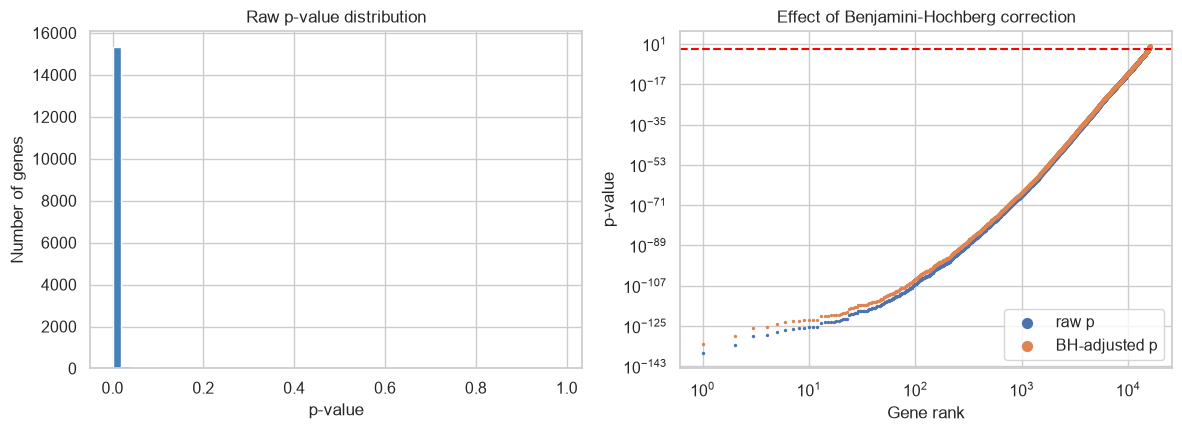

In [3]:
groups = [logcpm.loc[:, (meta["subtype"] == s).values].values for s in SUB_ORDER]
H, p = stats.kruskal(*groups, axis=1)
kw = pd.DataFrame({"H": H, "pvalue": p}, index=logcpm.index)
kw["padj_BH"] = multipletests(kw["pvalue"], method="fdr_bh")[1]
kw = kw.sort_values("pvalue")
kw.to_csv(TAB / "06_kruskal_wallis_all_genes.csv")
print(f"Kruskal-Wallis: {(kw['pvalue'] < 0.05).sum()} genes with raw p < 0.05, "
      f"{(kw['padj_BH'] < 0.05).sum()} genes with BH-FDR < 0.05 (out of {len(kw)})")
print(kw.head(10))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(kw["pvalue"], bins=50, color="steelblue")
axes[0].set(title="Raw p-value distribution", xlabel="p-value", ylabel="Number of genes")
axes[1].scatter(kw["pvalue"].rank(), kw["pvalue"], s=2, label="raw p")
axes[1].scatter(kw["pvalue"].rank(), kw["padj_BH"], s=2, label="BH-adjusted p")
axes[1].axhline(0.05, color="red", ls="--")
axes[1].set(xscale="log", yscale="log", title="Effect of Benjamini-Hochberg correction", xlabel="Gene rank", ylabel="p-value")
axes[1].legend(markerscale=5)
plt.tight_layout(); plt.savefig(FIG / "06_pvalue_distribution.png", dpi=200); plt.show()

# fit DESeq2. This takes about 1–3 minutes. Set n_cpus to the number of cores on your laptop

In [4]:
t = time.time()
md = meta.set_index("sample_id")[["subtype"]]
md["subtype"] = pd.Categorical(md["subtype"], categories=SUB_ORDER)   # LumA = reference level
dds = DeseqDataSet(counts=counts.T, metadata=md, design="~subtype",   # PyDESeq2 wants samples x genes
                   refit_cooks=True, inference=DefaultInference(n_cpus=4))
dds.deseq2()
print(f"DESeq2 fit finished in {(time.time() - t) / 60:.1f} min")

Fitting size factors...


Using None as control genes, passed at DeseqDataSet initialization


... done in 0.68 seconds.

Fitting dispersions...
... done in 9.33 seconds.

Fitting dispersion trend curve...
... done in 0.24 seconds.

Fitting MAP dispersions...
... done in 10.17 seconds.

Fitting LFCs...
... done in 8.57 seconds.

Calculating cook's distance...
... done in 1.44 seconds.

Replacing 1030 outlier genes.

Fitting dispersions...
... done in 0.75 seconds.

Fitting MAP dispersions...
... done in 0.64 seconds.

Fitting LFCs...


DESeq2 fit finished in 0.7 min


... done in 0.63 seconds.



# contrasts, each subtype vs LumA

In [5]:
results = {}
for s in ["LumB", "Her2", "Basal", "Normal"]:
    ds = DeseqStats(dds, contrast=["subtype", s, "LumA"], alpha=FDR, quiet=True,
                    inference=DefaultInference(n_cpus=4))
    ds.summary()                              # Wald test + BH-adjusted p-values
    ds.lfc_shrink(coeff=f"subtype[T.{s}]")    # apeGLM shrinkage of fold changes
    r = ds.results_df.copy()
    r["gene"] = genes.loc[r.index, "gene_name"].values
    r["sig"]  = np.select([(r["padj"] < FDR) & (r["log2FoldChange"] > LFC),
                           (r["padj"] < FDR) & (r["log2FoldChange"] < -LFC)], ["Up", "Down"], "NS")
    r = r.sort_values("padj")
    r.to_csv(TAB / f"06_DESeq2_{s}_vs_LumA.csv")
    results[s] = r

de_summary = pd.DataFrame({s: r["sig"].value_counts() for s, r in results.items()}).T.fillna(0).astype(int)
de_summary = de_summary.reindex(columns=["Up", "Down", "NS"])
de_summary.to_csv(TAB / "06_DE_summary.csv")
print("DE genes vs LumA (padj < 0.05, |log2FC| > 1):\n", de_summary)

DE genes vs LumA (padj < 0.05, |log2FC| > 1):
 sig       Up  Down     NS
LumB     370   546  15043
Her2     959  1042  13958
Basal   2151  1647  12161
Normal  1178   591  14190


# volcano plots

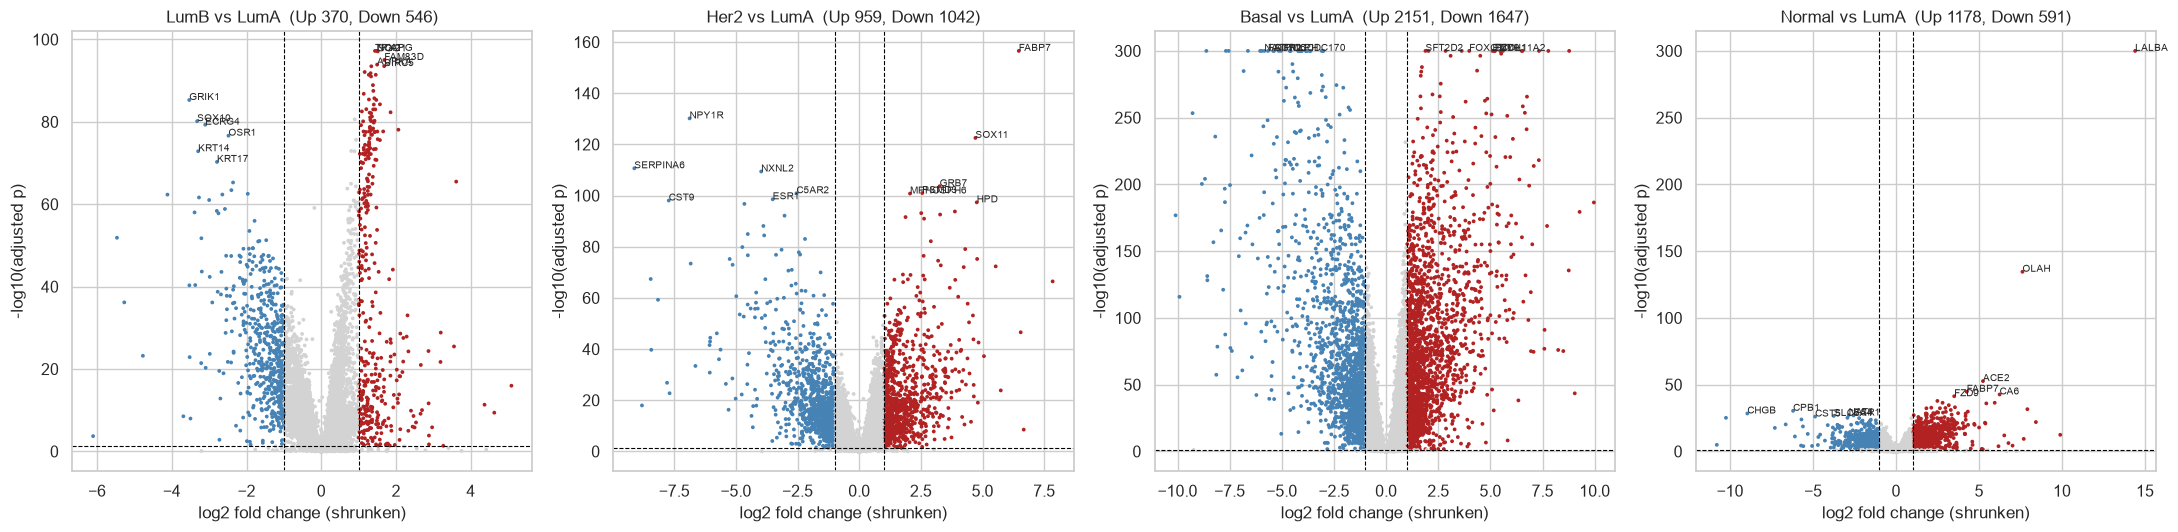

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
for ax, (s, r) in zip(axes, results.items()):
    r = r.dropna(subset=["padj"])
    y = -np.log10(r["padj"].clip(lower=1e-300))
    ax.scatter(r["log2FoldChange"], y, s=3, c=r["sig"].map({"Up": "firebrick", "Down": "steelblue", "NS": "lightgrey"}))
    ax.axhline(-np.log10(FDR), color="black", ls="--", lw=0.8)
    for v in (-LFC, LFC): ax.axvline(v, color="black", ls="--", lw=0.8)
    lab = pd.concat([r[r.sig == "Up"].nsmallest(6, "padj"), r[r.sig == "Down"].nsmallest(6, "padj")])
    for _, row in lab.iterrows():
        ax.annotate(row["gene"], (row["log2FoldChange"], -np.log10(max(row["padj"], 1e-300))), fontsize=7)
    n = de_summary.loc[s]
    ax.set(title=f"{s} vs LumA  (Up {n['Up']}, Down {n['Down']})",
           xlabel="log2 fold change (shrunken)", ylabel="-log10(adjusted p)")
plt.tight_layout(); plt.savefig(FIG / "06_volcano.png", dpi=200); plt.show()

# heatmap of the top DE genes

c:\Users\srika\Downloads\TCGA_BRCA_project\.venv\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


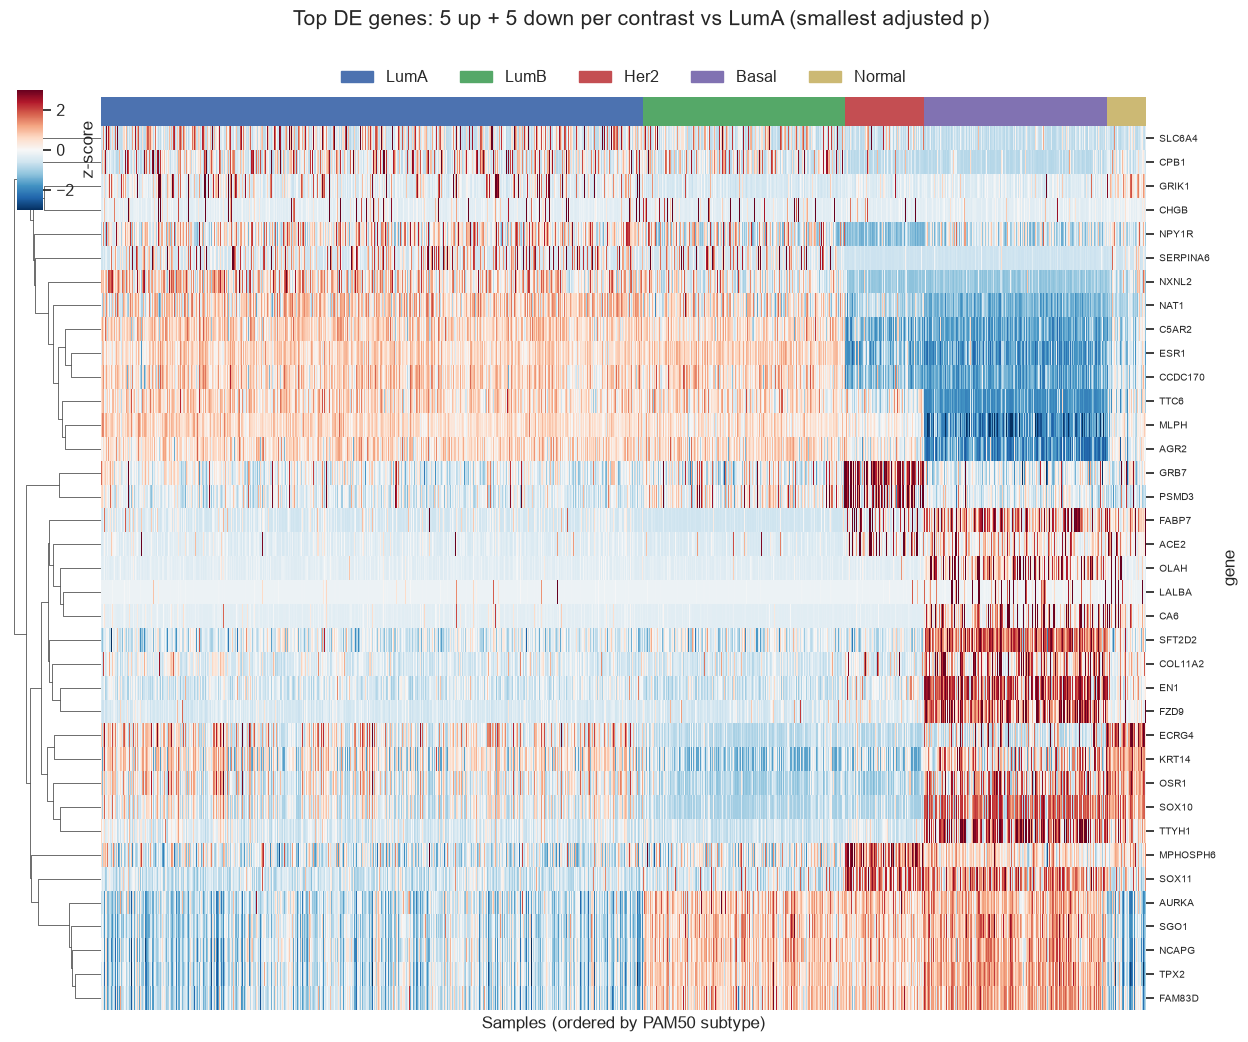

In [7]:
top = []
for s, r in results.items():
    top += list(r[r["sig"] == "Up"].nsmallest(5, "padj")["gene"]) + list(r[r["sig"] == "Down"].nsmallest(5, "padj")["gene"])
top = list(dict.fromkeys(g for g in top if g in logcpm.index))      # unique, keep order
order = meta.sort_values("subtype", key=lambda s: s.map({k: i for i, k in enumerate(SUB_ORDER)})).index
z = logcpm.loc[top, meta.loc[order, "sample_id"]]
z = z.sub(z.mean(axis=1), axis=0).div(z.std(axis=1), axis=0).clip(-3, 3)
cg = sns.clustermap(z, col_cluster=False, row_cluster=True, cmap="RdBu_r", center=0,
                    xticklabels=False, yticklabels=True,
                    col_colors=[meta.loc[order, "subtype"].map(PALETTE).values], figsize=(13, 10),
                    cbar_pos=(0.02, 0.82, 0.02, 0.12), cbar_kws={"label": "z-score"}, dendrogram_ratio=(0.08, 0.05))
cg.ax_heatmap.tick_params(axis="y", labelsize=7); cg.ax_heatmap.set_xlabel("Samples (ordered by PAM50 subtype)")
cg.ax_heatmap.legend(handles=[Patch(color=PALETTE[s], label=s) for s in SUB_ORDER], ncol=5,
                     loc="lower center", bbox_to_anchor=(0.5, 1.03), frameon=False)
cg.figure.suptitle("Top DE genes: 5 up + 5 down per contrast vs LumA (smallest adjusted p)", y=1.02)
cg.savefig(FIG / "06_DE_heatmap.png", dpi=200, bbox_inches="tight"); plt.show()